# Notebook 05 — Sensitivity: B2 safety margin and B1 fixed setpoint

Stage 5, the final analysis stage. Code: unchanged `src/controllers.py` (B1 `FixedSetpointPI`, B2 `LoadAdaptivePI`, simulator, metrics) on the plant from `src/thermal_model.py`.

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Scope and claim discipline</b><br>
<ul><li><b>Two one-at-a-time sweeps on the Stage 3 closed-cycle traces S1 and S2c, at both update intervals (60 s, 300 s):</b><ul><li>B2's safety margin $m\in\{0.5,1,1.5,2\}$ K;</li><li>B1's fixed setpoint $\in\{23,24,25\}$ °C.</li></ul></li><li>The Stage 2 gains, actuator limits, PI law and anti-windup are <b>unchanged</b>. Nothing is retuned, and no new controller or optimiser is introduced.</li><li><b>Each run starts at its own equilibrium</b> (its own setpoint at the starting load) and must return to it over the same 17 h horizon. Initial states therefore differ between runs, and each is printed.</li><li><b>Stricter safety rule than Stage 3:</b> a run counts as safe only if it stays within the limits on <b>both</b> the 5 s and the 1 s replay grids. A violation found on the finer grid cannot be overruled by the coarser one.</li><li>A signed saving against the fixed-24 °C B1 baseline is claimed only when <b>both</b> runs are complete, safe, settled and pass the terminal checks. Unsafe or unsettled runs are reported, but never ranked.</li><li>The Stage 4 OC results are <b>not</b> placed on the savings table or plot. Their start and end states differ from these runs, so they are discussed separately (§6).</li><li>Every number is a <b>model result with illustrative [ILL] parameters</b>. There is no real-facility validation.</li></ul>
</div>

<div style="background:#f1f1ef;border-left:6px solid #6b6b66;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>AI acknowledgement</b><br>
Drafted by Claude (Anthropic), used through Claude Code, at the team's request on 30 Oct 2026. The team must review it and be able to explain it. See <code>AI_USE_LOG.md</code>.
</div>

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..", "src").resolve()))
import thermal_model as tm
import controllers as ct

FIG_DIR = Path("..", "figures").resolve()
FIG_DIR.mkdir(exist_ok=True)
p = tm.Params()
H = 3600.0

# ---- declared before any run (identical to Stage 3 unless stated) ----
HORIZON = 17 * H        # common horizon, s
FINE_DT = 5.0           # main replay / quadrature grid, s (Stage 3)
FINE_DT_CHECK = 1.0     # finer safety grid, s (NEW: safety must hold on this grid too)
TOL_SETTLE = 0.1        # K
TOL_SAFETY = 1e-6       # K, on BOTH grids
TOL_TERMINAL = 1e-3     # K
TOL_DU = 1e-4           # |dU| max g <= TOL_DU E_cool
TOL_EQ = 1e-14          # K/s: residual of the starting equilibrium
T_A_BAND, T_S_MAX = (18.0, 27.0), 40.0
DTS = (60, 300)
MARGINS = (0.5, 1.0, 1.5, 2.0)      # B2 margin m, K
SETPOINTS = (23.0, 24.0, 25.0)      # B1 fixed setpoint, degC
BASELINE = ("B1", 24.0)             # the Stage 3 baseline every B2 margin is compared with

results, findings = [], []


def record(cid, desc, value, criterion, passed):
    # non-fatal: every check is logged; the summary reports PASS/FAIL truthfully
    results.append((cid, desc, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {cid}: {desc}\n        measured: {value}   criterion: {criterion}")


def finding(fid, text):
    findings.append((fid, text))
    print(f"[FINDING] {fid}: {text}")


print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__}")
print(f"horizon {HORIZON/H:.0f} h; grids {FINE_DT} s (energy, settling) and {FINE_DT_CHECK} s (safety, refinement); "
      f"settling band +/-{TOL_SETTLE} K; safety tolerance {TOL_SAFETY} K on both grids;")
print(f"terminal tolerance {TOL_TERMINAL} K; dU bound {TOL_DU:.0e} x E_cool; limits: air {T_A_BAND[0]}-{T_A_BAND[1]} C, equipment <= {T_S_MAX} C")
print(f"B2 margins {MARGINS} K; B1 setpoints {SETPOINTS} C; update intervals {DTS} s; gains: stored Stage 2 values (not retuned)")

numpy 2.5.4, matplotlib 3.11.2
horizon 17 h; grids 5.0 s (energy, settling) and 1.0 s (safety, refinement); settling band +/-0.1 K; safety tolerance 1e-06 K on both grids;
terminal tolerance 0.001 K; dU bound 1e-04 x E_cool; limits: air 18.0-27.0 C, equipment <= 40.0 C
B2 margins (0.5, 1.0, 1.5, 2.0) K; B1 setpoints (23.0, 24.0, 25.0) C; update intervals (60, 300) s; gains: stored Stage 2 values (not retuned)


## 1. The two sweeps and what each one isolates

| Sweep | Varies | Fixed | What it isolates |
|---|---|---|---|
| **B2 margin** $m$ | $T_{set}=\mathrm{clip}\big(\min(27,\ 40-P_{IT}/UA_s)-m,\ 18,\ 27\big)$, recomputed at every update from the measured load | PI law, gains, limits | How much energy each kelvin of safety margin costs, and how much safety it buys |
| **B1 setpoint** | constant $T_{set}\in\{23,24,25\}$ °C | the same | The effect of simply running **warmer all the time**, with no load measurement |

Comparing the two separates "a warmer fixed setpoint" from "load adaptation".

- B1 at 25 °C runs warmer than B2 with $m=1$ at 1.0 MW (24 °C), but cooler at 0.6–0.8 MW (26 °C).
- At steady state, B1 at 25 °C and 1.0 MW puts the lumped equipment at **exactly** 40 °C ($25+15$), with zero margin. Transients can therefore push it over the limit.

**Setpoints implied by the rule (°C):**

| $m$ (K) | 0.6 MW | 0.8 MW | 1.0 MW |
|---|---|---|---|
| 0.5 | 26.5 | 26.5 | 24.5 |
| 1.0 | 26.0 | 26.0 | 24.0 |
| 1.5 | 25.5 | 25.5 | 23.5 |
| 2.0 | 25.0 | 25.0 | 23.0 |

In [2]:
for m in MARGINS:
    sp = [ct.adaptive_setpoint(P, p.UA_s, margin=m) for P in (0.6e6, 0.8e6, 1.0e6)]
    expect = [min(27.0, 40.0 - P / p.UA_s) - m for P in (0.6e6, 0.8e6, 1.0e6)]
    record(f"SP-m{m:g}", f"B2 setpoints at 0.6 / 0.8 / 1.0 MW with margin {m:g} K", " / ".join(f"{s:.2f}" for s in sp) + " C",
           " / ".join(f"{e:.2f}" for e in expect) + " C", np.allclose(sp, expect, atol=1e-12))

[PASS] SP-m0.5: B2 setpoints at 0.6 / 0.8 / 1.0 MW with margin 0.5 K
        measured: 26.50 / 26.50 / 24.50 C   criterion: 26.50 / 26.50 / 24.50 C
[PASS] SP-m1: B2 setpoints at 0.6 / 0.8 / 1.0 MW with margin 1 K
        measured: 26.00 / 26.00 / 24.00 C   criterion: 26.00 / 26.00 / 24.00 C
[PASS] SP-m1.5: B2 setpoints at 0.6 / 0.8 / 1.0 MW with margin 1.5 K
        measured: 25.50 / 25.50 / 23.50 C   criterion: 25.50 / 25.50 / 23.50 C
[PASS] SP-m2: B2 setpoints at 0.6 / 0.8 / 1.0 MW with margin 2 K
        measured: 25.00 / 25.00 / 23.00 C   criterion: 25.00 / 25.00 / 23.00 C


## 2. Runs: same traces, horizon, gains and limits as Stage 3

- The closed-cycle traces S1 and S2c are identical to Stage 3.
- Every run is simulated twice:
  - on the 5 s grid, which is used for electricity (Simpson) and settling, exactly as in Stage 3;
  - on a 1 s grid, used for safety and refinement.
- The starting state is printed for every run.

In [3]:
PD = ct.PiecewiseDisturbance
CMP = {
    "S1":  dict(dist=PD([0, 1*H, 9*H], [0.6e6, 1.0e6, 0.6e6], [30.0, 30.0, 30.0]),
                events=[(1*H, 9*H), (9*H, HORIZON)], title="S1: load 0.6 → 1.0 → 0.6 MW, $T_{out}$ 30 °C"),
    "S2c": dict(dist=PD([0, 1*H, 9*H], [0.8e6, 0.8e6, 0.8e6], [30.0, 35.0, 30.0]),
                events=[(1*H, 9*H), (9*H, HORIZON)], title="S2c: 0.8 MW, $T_{out}$ 30 → 35 → 30 °C"),
}
CTRLS = [("B1", v) for v in SETPOINTS] + [("B2", m) for m in MARGINS]


def name(kind, v):
    return f"B1 {v:.0f} C" if kind == "B1" else f"B2 m={v:g} K"


def make_ctrl(kind, v, dt, P0):
    g = ct.STAGE2_GAINS[dt]
    if kind == "B1":
        return ct.FixedSetpointPI(g, v, Q_min=0.0, Q_max=p.Q_max)
    return ct.LoadAdaptivePI(g, ct.adaptive_setpoint(P0, p.UA_s, margin=v), Q_min=0.0, Q_max=p.Q_max, UA_s=p.UA_s, margin=v)


def run(kind, v, dt, dist, fine_dt):
    P0, To0 = dist.at(0.0)
    ctrl = make_ctrl(kind, v, dt, P0)
    Q0 = tm.holding_cooling(p, ctrl.T_set, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)
    ctrl.initialize(Q0)
    res = ct.simulate_closed_loop(p, ctrl, dist, x0, HORIZON, fine_dt=fine_dt)
    res.meta["x0"], res.meta["Q0"], res.meta["w0"] = x0, Q0, np.array([Q0, P0, To0])
    return res


R5, R1 = {}, {}
for sid, s in CMP.items():
    for dt in DTS:
        for kind, v in CTRLS:
            R5[(sid, dt, kind, v)] = run(kind, v, dt, s["dist"], FINE_DT)
            R1[(sid, dt, kind, v)] = run(kind, v, dt, s["dist"], FINE_DT_CHECK)
print("initial states (each run starts at its OWN equilibrium; identical for both update intervals):")
for sid in CMP:
    for kind, v in CTRLS:
        r = R5[(sid, 60, kind, v)]
        print(f"  {sid:3s} {name(kind, v):10s}: T_a = {r.meta['x0'][1]:.2f} C, T_s = {r.meta['x0'][0]:.2f} C, Q_c = {r.meta['Q0']/1e6:.4f} MW_th")
print("status:", {k: v.status for k, v in R5.items() if v.status != "completed"} or "all runs completed")

initial states (each run starts at its OWN equilibrium; identical for both update intervals):
  S1  B1 23 C   : T_a = 23.00 C, T_s = 32.00 C, Q_c = 0.6140 MW_th
  S1  B1 24 C   : T_a = 24.00 C, T_s = 33.00 C, Q_c = 0.6120 MW_th
  S1  B1 25 C   : T_a = 25.00 C, T_s = 34.00 C, Q_c = 0.6100 MW_th
  S1  B2 m=0.5 K: T_a = 26.50 C, T_s = 35.50 C, Q_c = 0.6070 MW_th
  S1  B2 m=1 K  : T_a = 26.00 C, T_s = 35.00 C, Q_c = 0.6080 MW_th
  S1  B2 m=1.5 K: T_a = 25.50 C, T_s = 34.50 C, Q_c = 0.6090 MW_th
  S1  B2 m=2 K  : T_a = 25.00 C, T_s = 34.00 C, Q_c = 0.6100 MW_th
  S2c B1 23 C   : T_a = 23.00 C, T_s = 35.00 C, Q_c = 0.8140 MW_th
  S2c B1 24 C   : T_a = 24.00 C, T_s = 36.00 C, Q_c = 0.8120 MW_th
  S2c B1 25 C   : T_a = 25.00 C, T_s = 37.00 C, Q_c = 0.8100 MW_th
  S2c B2 m=0.5 K: T_a = 26.50 C, T_s = 38.50 C, Q_c = 0.8070 MW_th
  S2c B2 m=1 K  : T_a = 26.00 C, T_s = 38.00 C, Q_c = 0.8080 MW_th
  S2c B2 m=1.5 K: T_a = 25.50 C, T_s = 37.50 C, Q_c = 0.8090 MW_th
  S2c B2 m=2 K  : T_a = 25.00 C, T_

## 3. Verification

| ID | Check |
|---|---|
| EQ | Every starting state is a true equilibrium of its own setpoint and starting load |
| S3R | B1 at 24 °C and B2 with $m=1$ reproduce the Stage 3 table exactly (8 runs; every printed field) |
| E | Thermal energy balance $E_Q=E_{IT}+E_{env}-\Delta U$; heat removed $=\sum Q_c h$ |
| G | Integration refinement, 5 s vs 1 s: $E_{cool}$ and temperature extrema (Stage 3 criteria) |
| Q | $E_{cool}$ re-computed independently: `simulate_zoh` on a 0.5 s grid plus trapezoid quadrature |
| T | Terminal closure: the run returns to its own start state; $\Delta U$ negligible |

In [4]:
A_, _, _, G_ = tm.system_matrices(p)
for key, r in R5.items():
    res = float(np.max(np.abs(A_ @ r.meta["x0"] + G_ @ r.meta["w0"])))
    record(f"EQ-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: start is an equilibrium",
           f"{res:.1e} K/s", f"< {TOL_EQ:.0e} K/s", res < TOL_EQ)

nb3 = json.loads(Path("03_load_adaptive_pi_energy.ipynb").read_text())
txt3 = "\n".join("".join(o.get("text", "")) for c in nb3["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
S3 = {(m[1], int(m[2]), m[3]): m.groups()[3:]
      for m in re.finditer(r"^(S1|S2c) (60|300)s (B1|B2)\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)\.\.\s*(\S+)\s+(\S+)", txt3, re.M)}
for sid in CMP:
    for dt in DTS:
        for kind, v in (("B1", 24.0), ("B2", 1.0)):
            r = R5[(sid, dt, kind, v)]
            e, lv = ct.energy_summary(p, r), ct.limit_violations(r, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
            now = (f"{e['E_cool_kWh_e']:.1f}", f"{e['E_Q_kWh_th']:.1f}", f"{e['E_IT_kWh_e']:.1f}", f"{e['cool_to_IT_ratio']:.3f}",
                   f"{e['peak_P_cool_kW_e']:.1f}", f"{lv['T_a_min']:.2f}", f"{lv['T_a_max']:.2f}", f"{lv['T_s_max']:.2f}")
            record(f"S3R-{sid}-{dt}-{kind}", f"{sid} dt={dt}s {name(kind, v)} reproduces the Stage 3 table "
                   "(E_cool, E_Q, E_IT, ratio, peak, T_a min/max, T_s max)", f"now {now}; notebook 03 {S3.get((sid, dt, kind))}",
                   "identical", S3.get((sid, dt, kind)) == now)

for key, r in R5.items():
    rel = abs(tm.energy_balance_residual(p, r.X)) / r.X[-1, 3]
    relQ = abs(np.sum(r.Q[:-1] * np.diff(r.t)) - (r.X[-1, 2] - r.X[0, 2])) / r.X[-1, 2]
    record(f"E-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: energy balance; heat removed = sum(Q h)",
           f"{rel:.1e}, {relQ:.1e}", "< 1e-9, < 1e-9", rel < 1e-9 and relQ < 1e-9)

for key, r5 in R5.items():
    r1 = R1[key]
    d_ext = max(abs(r1.X[:, 1].max() - r5.X[:, 1].max()), abs(r1.X[:, 1].min() - r5.X[:, 1].min()), abs(r1.X[:, 0].max() - r5.X[:, 0].max()))
    d_E = abs(r1.E_cool[-1] - r5.E_cool[-1]) / r1.E_cool[-1]
    record(f"G-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: 5 s vs 1 s grid: extrema; Simpson E_cool",
           f"extrema {d_ext:.1e} K, E_cool rel {d_E:.1e}", "< 0.01 K, < 1e-6", d_ext < 0.01 and d_E < 1e-6)


def independent_E_cool(res, dist, h=0.5):
    t_end = res.t[-1]
    grid = np.unique(np.concatenate([np.arange(0.0, t_end, h), res.log["t"], dist.times[dist.times < t_end], [t_end]]))
    k = np.searchsorted(res.log["t"], grid[:-1], side="right") - 1
    Q = res.log["u"][k]
    PT = np.array([dist.at(t) for t in grid[:-1]])
    X = tm.simulate_zoh(p, res.meta["x0"], grid, np.column_stack([Q, PT[:, 0], PT[:, 1]]))
    on = Q > 0
    gl = np.zeros_like(Q); gr = np.zeros_like(Q)
    gl[on] = 1.0 / tm.cop(p, X[:-1, 1][on], PT[on, 1])
    gr[on] = 1.0 / tm.cop(p, X[1:, 1][on], PT[on, 1])
    return np.sum(Q * np.diff(grid) * 0.5 * (gl + gr))


for key, r in R5.items():
    rel = abs(independent_E_cool(r, CMP[key[0]]["dist"]) - r.E_cool[-1]) / r.E_cool[-1]
    record(f"Q-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: Simpson vs independent 0.5 s trapezoid",
           f"rel diff {rel:.1e}", "< 1e-5", rel < 1e-5)


def assess(key):
    r5, r1 = R5[key], R1[key]
    e = ct.energy_summary(p, r5)
    v5 = ct.limit_violations(r5, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    v1 = ct.limit_violations(r1, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    on = r5.Q[:-1] > 0
    g_max = np.nanmax(r5.P_cool[:-1][on] / r5.Q[:-1][on]) if on.any() else 0.0
    settle = [ct.event_metrics(r5, a, b, tol=TOL_SETTLE)["settling_time"] for (a, b) in CMP[key[0]]["events"]]
    term_ok = (abs(e["dT_s_end_K"]) <= TOL_TERMINAL and abs(e["dT_a_end_K"]) <= TOL_TERMINAL
               and abs(e["dU_J"]) * g_max <= TOL_DU * r5.E_cool[-1])
    headroom = min(T_A_BAND[1] - v1["T_a_max"], v1["T_a_min"] - T_A_BAND[0], T_S_MAX - v1["T_s_max"])
    safe = v5["within_limits"] and v1["within_limits"]
    settled = all(s is not None for s in settle)
    reasons = ([] if e["complete"] else ["stopped"]) + \
              ([] if v5["within_limits"] else ["unsafe on 5 s grid"]) + \
              ([] if v1["within_limits"] or not v5["within_limits"] else ["unsafe on 1 s grid only"]) + \
              ([] if settled else ["not settled"]) + ([] if term_ok else ["terminal check failed"])
    return {"e": e, "v5": v5, "v1": v1, "settle": settle, "settled": settled, "term_ok": term_ok, "safe": safe,
            "headroom": headroom, "eligible": not reasons, "reasons": reasons}


AS = {key: assess(key) for key in R5}
for key, a in AS.items():
    record(f"T-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: returns to its own start state; dU negligible",
           f"dT_s {a['e']['dT_s_end_K']:.1e} K, dT_a {a['e']['dT_a_end_K']:.1e} K, dU {a['e']['dU_J']:.2e} J",
           f"|dT| <= {TOL_TERMINAL} K, |dU| max g <= {TOL_DU:.0e} E_cool", a["term_ok"])

[PASS] EQ-S1-60-B123: S1 dt=60s B1 23 C: start is an equilibrium
        measured: 8.3e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B124: S1 dt=60s B1 24 C: start is an equilibrium
        measured: 5.6e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B125: S1 dt=60s B1 25 C: start is an equilibrium
        measured: 8.3e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B20.5: S1 dt=60s B2 m=0.5 K: start is an equilibrium
        measured: 1.1e-16 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B21: S1 dt=60s B2 m=1 K: start is an equilibrium
        measured: 5.6e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B21.5: S1 dt=60s B2 m=1.5 K: start is an equilibrium
        measured: 8.3e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-60-B22: S1 dt=60s B2 m=2 K: start is an equilibrium
        measured: 8.3e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-300-B123: S1 dt=300s B1 23 C: start is an equilibrium
        measured: 8.3e-17 K/s   criterion: < 1e-14 K/s
[PASS] EQ-S1-300-B124: S1 dt=3

[PASS] Q-S1-60-B123: S1 dt=60s B1 23 C: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 5.1e-08   criterion: < 1e-5


[PASS] Q-S1-60-B124: S1 dt=60s B1 24 C: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 4.5e-08   criterion: < 1e-5


[PASS] Q-S1-60-B125: S1 dt=60s B1 25 C: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 3.9e-08   criterion: < 1e-5


[PASS] Q-S1-60-B20.5: S1 dt=60s B2 m=0.5 K: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 3.9e-08   criterion: < 1e-5


...

[PASS] Q-S2c-300-B125: S2c dt=300s B1 25 C: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 7.1e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B20.5: S2c dt=300s B2 m=0.5 K: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 6.1e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B21: S2c dt=300s B2 m=1 K: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 6.5e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B21.5: S2c dt=300s B2 m=1.5 K: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 6.8e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B22: S2c dt=300s B2 m=2 K: Simpson vs independent 0.5 s trapezoid
        measured: rel diff 7.1e-08   criterion: < 1e-5
[PASS] T-S1-60-B123: S1 dt=60s B1 23 C: returns to its own start state; dU negligible
        measured: dT_s 1.7e-09 K, dT_a 3.0e-12 K, dU 4.36e-02 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool
[PASS] T-S1-60-B124: S1 dt=60s B1 24 C: returns to its own start state; dU negligible
        measured: dT_s 1.5e-09 K, dT_a 2.6e-12 K, dU 3.74e-02 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool
[PASS] T-S1-60-B125: S1 dt=60s B1 25 C: returns to its own start state; dU negligible
        measured: dT_s 1.2e-09 K, dT_a 2.1e-12 K, dU 3.12e-02 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool
[PASS] T-S1-60-B20.5: S1 dt=60s B2 m=0.5 K: returns to its own start state; dU negligible
        measured: dT_s 1.1e-09 K, dT_a 1.5e-12 K, dU 2.77e-02 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool
[PASS] T-S1-60-B21: S1 dt=60s 

## 4. Results: one compact table

- **Columns:** start state; cooling electricity $E_{cool}$ (kWh$_e$, 5 s Simpson); signed saving against the fixed-24 °C B1 baseline; air min/max and equipment max (°C, 1 s grid); largest limit exceedance on the 5 s and 1 s grids (K); degree-hours above 27 °C / below 18 °C / above 40 °C (K h, 1 s grid); settling; terminal mismatch $\max|\Delta T|$ (K); $\Delta U$ (J); status.
- **"headroom"** $=\min(27-T_{a,\max},\ T_{a,\min}-18,\ 40-T_{s,\max})$ on the 1 s grid. A negative value means a limit is exceeded.
- **Savings:** a signed saving appears only when the run **and** the baseline (same scenario and interval) are both eligible.
- **B1 sweep:** the B1 rows show the setpoint effect alone, against the same baseline.

In [5]:
hdr = (f"{'run':22s} {'start T_a/T_s':>13s} {'E_cool':>7s} {'vs B1-24':>9s} {'T_a min..max':>13s} {'T_s max':>7s} {'headroom':>8s} "
       f"{'maxV 5s':>7s} {'maxV 1s':>7s} {'DH>27':>6s} {'DH<18':>6s} {'DH>40':>6s} {'settle':>6s} {'dT_end':>7s} {'dU':>8s}  status")
units = (f"{'':22s} {'C':>13s} {'kWh_e':>7s} {'%':>9s} {'C (1 s)':>13s} {'C (1 s)':>7s} {'K (1 s)':>8s} {'K':>7s} {'K':>7s} "
         f"{'K h':>6s} {'K h':>6s} {'K h':>6s} {'':>6s} {'K':>7s} {'J':>8s}")
TAB = ["SENSITIVITY (model results, illustrative parameters; common 17 h horizon; each run starts/ends at its own equilibrium)", hdr, units]
SAV = {}


def mv(v):
    return max(v["max_T_a_over"], v["max_T_a_under"], v["max_T_s_over"])


for sid in CMP:
    for dt in DTS:
        base = AS[(sid, dt) + BASELINE]
        for block, kinds in (("B2 margin sweep", "B2"), ("B1 setpoint sweep (setpoint effect only)", "B1")):
            TAB.append(f"-- {sid} {dt}s: {block}")
            for kind, v in CTRLS:
                if kind != kinds:
                    continue
                key = (sid, dt, kind, v)
                a, r = AS[key], R5[key]
                e, v5, v1 = a["e"], a["v5"], a["v1"]
                if (kind, v) == BASELINE:
                    sav = "baseline"
                elif a["eligible"] and base["eligible"]:
                    s_ = (base["e"]["E_cool_kWh_e"] - e["E_cool_kWh_e"]) / base["e"]["E_cool_kWh_e"]
                    SAV[key] = s_
                    sav = f"{100*s_:+.2f}"
                else:
                    sav = "n/a"
                dT = max(abs(e["dT_s_end_K"]), abs(e["dT_a_end_K"]))
                status = "eligible" if a["eligible"] else "NOT eligible: " + ", ".join(a["reasons"])
                if a["eligible"] and not base["eligible"]:
                    status += " (baseline not eligible: no saving)"
                TAB.append(f"{name(kind, v):22s} {r.meta['x0'][1]:6.2f}/{r.meta['x0'][0]:5.2f} {e['E_cool_kWh_e']:7.1f} {sav:>9s} "
                           f"{v1['T_a_min']:6.2f}..{v1['T_a_max']:5.2f} {v1['T_s_max']:7.2f} {a['headroom']:8.3f} {mv(v5):7.3f} {mv(v1):7.3f} "
                           f"{v1['T_a_above_max_Kh']:6.3f} {v1['T_a_below_min_Kh']:6.3f} {v1['T_s_above_max_Kh']:6.3f} "
                           f"{'yes' if a['settled'] else 'NO':>6s} {dT:7.1e} {e['dU_J']:8.1e}  {status}")
print("\n".join(TAB))
for key, a in AS.items():
    if a["v5"]["within_limits"] and not a["v1"]["within_limits"]:
        finding(f"F-1s-{key[0]}-{key[1]}-{key[2]}{key[3]:g}", f"{key[0]} dt={key[1]}s {name(*key[2:])}: safe on the 5 s grid but NOT on the 1 s grid "
                f"(max exceedance {mv(a['v1']):.2e} K); treated as unsafe")

SENSITIVITY (model results, illustrative parameters; common 17 h horizon; each run starts/ends at its own equilibrium)
run                    start T_a/T_s  E_cool  vs B1-24  T_a min..max T_s max headroom maxV 5s maxV 1s  DH>27  DH<18  DH>40 settle  dT_end       dU  status
                                   C   kWh_e         %       C (1 s) C (1 s)  K (1 s)       K       K    K h    K h    K h              K        J
-- S1 60s: B2 margin sweep
B2 m=0.5 K              26.50/35.50  2595.8     +5.83  24.50..26.50   39.50    0.500   0.000   0.000  0.000  0.000  0.000    yes 1.1e-09  2.8e-02  eligible
B2 m=1 K                26.00/35.00  2656.2     +3.64  24.00..26.00   39.00    1.000   0.000   0.000  0.000  0.000  0.000    yes 1.2e-09  3.1e-02  eligible
B2 m=1.5 K              25.50/34.50  2717.1     +1.43  23.50..25.50   38.50    1.500   0.000   0.000  0.000  0.000  0.000    yes 1.4e-09  3.4e-02  eligible
B2 m=2 K                25.00/34.00  2778.2     -0.79  23.00..25.00   38.00    2.000

## 5. Figure: energy vs safety headroom

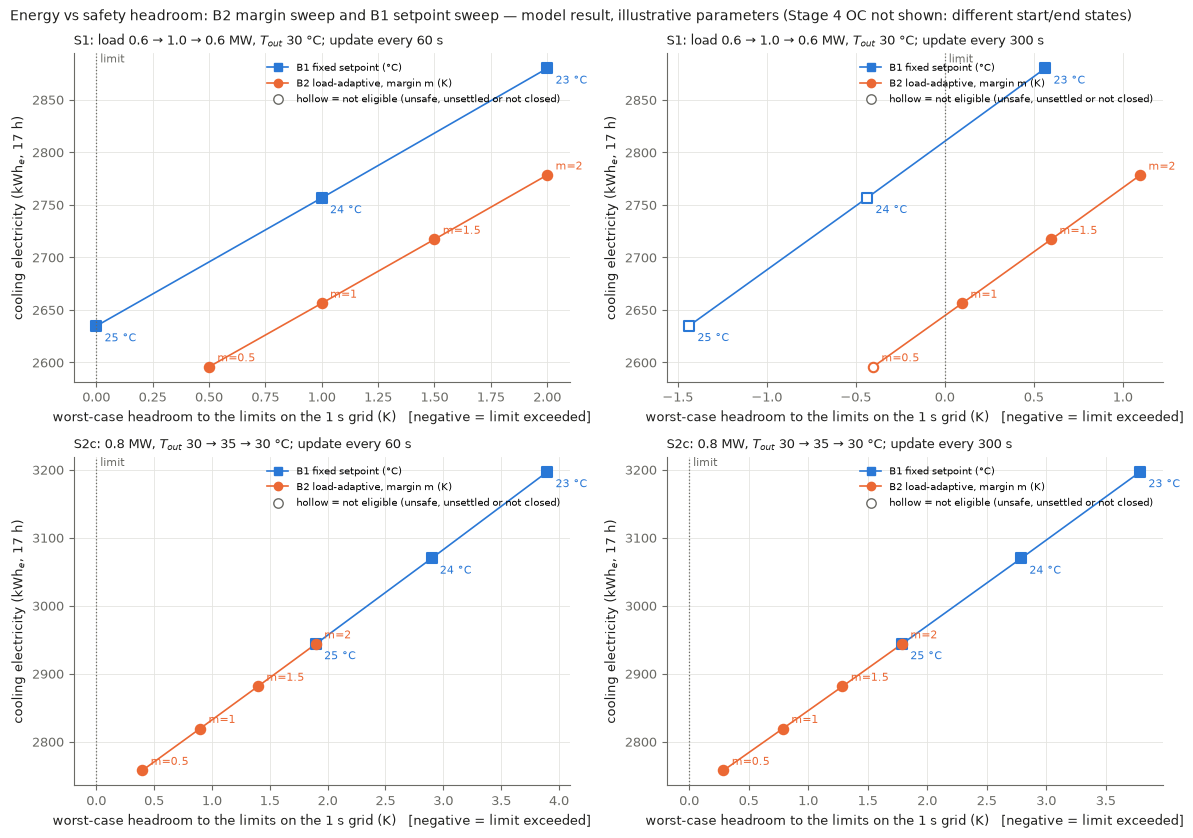

saved: fig14_sensitivity_energy_headroom.png and .eps


In [6]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1d", "#6b6b66", "#e4e4e0"
plt.rcParams.update({"font.size": 9.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})
fig, axs = plt.subplots(2, 2, figsize=(12, 8.5))
for i, sid in enumerate(CMP):
    for j, dt in enumerate(DTS):
        ax = axs[i, j]
        for kind, col, mk, lab in (("B1", BLUE, "s", "B1 fixed setpoint (°C)"), ("B2", ORANGE, "o", "B2 load-adaptive, margin m (K)")):
            keys = [(sid, dt, k, v) for k, v in CTRLS if k == kind]
            x = [AS[k]["headroom"] for k in keys]
            y = [AS[k]["e"]["E_cool_kWh_e"] for k in keys]
            ax.plot(x, y, color=col, lw=1.2, zorder=1)
            for k, xx, yy in zip(keys, x, y):
                ok = AS[k]["eligible"]
                ax.scatter([xx], [yy], s=46, marker=mk, color=col if ok else "white", edgecolor=col, linewidth=1.5, zorder=2)
                txt = f"{k[3]:.0f} °C" if kind == "B1" else f"m={k[3]:g}"
                ax.annotate(txt, (xx, yy), textcoords="offset points", xytext=(6, 4 if kind == "B2" else -11), fontsize=8, color=col)
            ax.plot([], [], color=col, marker=mk, lw=1.2, label=lab)
        ax.axvline(0.0, color=MUTED, ls=":", lw=0.9)
        ax.text(0.0, ax.get_ylim()[1], " limit", color=MUTED, fontsize=8, va="top")
        ax.set_title(f"{CMP[sid]['title']}; update every {dt} s", loc="left", color=INK, fontsize=9)
        ax.set_xlabel("worst-case headroom to the limits on the 1 s grid (K)   [negative = limit exceeded]")
        ax.set_ylabel("cooling electricity (kWh$_e$, 17 h)")
        ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
        ax.scatter([], [], s=46, marker="o", color="white", edgecolor=MUTED, label="hollow = not eligible (unsafe, unsettled or not closed)")
        ax.legend(frameon=False, fontsize=7.5, loc="upper right")
fig.suptitle("Energy vs safety headroom: B2 margin sweep and B1 setpoint sweep — model result, illustrative parameters "
             "(Stage 4 OC not shown: different start/end states)", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig14_sensitivity_energy_headroom.png", dpi=150)
fig.savefig(FIG_DIR / "fig14_sensitivity_energy_headroom.eps")
plt.show()
print("saved: fig14_sensitivity_energy_headroom.png and .eps")

## 6. Stage 4 OC results, discussed separately (not a matched comparison)

The Stage 4 benchmark ran with **B2 ($m=1$) start/end states** (the B2 protocol) and with B1-24 states (the B1 protocol). For every margin other than $m=1$, and for B1 at 23 or 25 °C, those states differ from the runs above. The OC numbers are therefore **not** placed on the table or figure as matched comparisons.

Below they are read directly from notebook 04's verified output, with their caveats:

- offline perfect foresight;
- zero margin;
- eligibility on the 5 s grid only, so the listed 1 s exceedances mean the S1 OC-ISC5 runs are **not** continuously safe, and under this notebook's stricter rule they would not be eligible;
- at 60 s, the J$_d$ artefact.

In [7]:
nb4 = json.loads(Path("04_perfect_foresight_benchmark.ipynb").read_text())
txt4 = "\n".join("".join(o.get("text", "")) for c in nb4["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
summary4 = txt4[txt4.rfind("STAGE 4 (perfect-foresight benchmark) VERIFICATION SUMMARY"):]
rows = [l for l in summary4.splitlines() if re.match(r"^(S1|S2c) (60|300)s B2-prot OC", l)]
fine = [l for l in summary4.splitlines() if l.startswith(("S1 ", "S2c ")) and "1 s grid" in l]
print("Stage 4 OC, B2 protocol (start/end at B2 m=1 equilibrium), copied from notebook 04's final summary:")
print("  run                         E_cool kWh_e   J_d kWh_e   T_a min..max   T_s max")
for l in rows:
    f = l.split()
    print(f"  {' '.join(f[:4]):27s} {f[4]:>12s} {f[5]:>11s} {f[10]:>14s} {f[11]:>9s}")
print("Known 1 s-grid exceedances of Stage 4 runs that pass on the 5 s grid:")
print("\n".join("  " + l for l in fine) or "  none")

Stage 4 OC, B2 protocol (start/end at B2 m=1 equilibrium), copied from notebook 04's final summary:
  run                         E_cool kWh_e   J_d kWh_e   T_a min..max   T_s max
  S1 300s B2-prot OC                2535.5      2535.0   24.80..27.65     40.09
  S1 300s B2-prot OC-ISC5           2536.3      2535.9   24.91..27.00     40.00
  S1 60s B2-prot OC                 2554.9      2500.1   20.15..27.08     40.05
  S1 60s B2-prot OC-ISC5            2550.4      2502.6   20.15..27.00     40.00
  S2c 300s B2-prot OC               2698.2      2698.1   24.91..27.00     39.00
  S2c 300s B2-prot OC-ISC5          2698.2      2698.1   24.91..27.00     39.00
  S2c 60s B2-prot OC                2697.6      2697.1   20.15..27.00     39.00
  S2c 60s B2-prot OC-ISC5           2697.6      2697.1   20.15..27.00     39.00
Known 1 s-grid exceedances of Stage 4 runs that pass on the 5 s grid:
  S1 300s B1-protocol OC-ISC5: within limits on the 5 s grid, but on the 1 s grid T_a max 27.000048 C (+4.75e-

### Interpretation
<div style="background:#fdf6e3;border-left:6px solid #c98500;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Energy versus safety margin (model behaviour, illustrative parameters)</b><br>
<ol>
<li><b>Energy versus margin is close to linear: safety margin costs energy at a steady rate.</b>
<ul>
<li>Each extra 0.5 K of B2 margin costs about 60–61 kWh<sub>e</sub> over 17 h in S1 (2595.8 → 2656.2 → 2717.1 → 2778.2 kWh<sub>e</sub> at 60 s). In S2c it costs about 62 kWh<sub>e</sub> (2757.6 → 2819.3 → 2881.3 → 2943.7).</li>
<li>That is roughly 2 % of the B1-24 baseline per 0.5 K. The same holds along the B1 setpoint sweep (about ±4.1–4.5 % per 1 K).</li>
<li>Nothing here is free: every kWh saved is bought with headroom to the illustrative limits.</li>
</ul></li>
<li><b>Load adaptation versus simply running warmer: they differ only when the load varies.</b>
<ul>
<li><b>S1, load varies.</b> At equal worst-case headroom, B2 uses about 100 kWh<sub>e</sub> less than B1: 2656.2 vs 2756.5 kWh<sub>e</sub> at 1.0 K headroom (m = 1 vs 24 °C), and 2778.2 vs 2879.7 at 2.0 K (m = 2 vs 23 °C), at 60 s.
<ul>
<li>A fixed setpoint must be safe at peak load, so it is too cold at low load.</li>
<li>To get close to B2 (m = 1) on energy, B1 must move to 25 °C. That leaves <b>zero</b> headroom at 60 s: the equipment settles exactly on 40 °C at 1.0 MW, inside the 1e-6 K tolerance only by round-off. At 300 s it is unsafe (+1.44 K).</li>
</ul></li>
<li><b>S2c, constant 0.8 MW load.</b> There is nothing to adapt to. B2 with m = 2 and B1 at 25 °C are the same controller and give identical results (2943.7 kWh<sub>e</sub>).
<ul>
<li>B2's S2c "saving" over B1-24 is therefore entirely a warmer setpoint, which B1 could also use safely here: B1-24 keeps 2.8–2.9 K headroom, because it is sized for 1 MW.</li>
</ul></li>
</ul></li>
<li><b>The update interval matters for safety more than for energy.</b>
<ul>
<li>The energies at 60 s and 300 s agree to within 0.3 kWh<sub>e</sub>.</li>
<li>In S1 at 300 s, three runs exceed a limit: the B1-24 baseline (T<sub>a</sub> 27.44 °C), B1 at 25 °C, and B2 with m = 0.5 (T<sub>a</sub> 27.40 °C, T<sub>s</sub> 40.27 °C).</li>
<li>B2 with m = 1 keeps only 0.10 K headroom.</li>
<li>Because the baseline itself is unsafe, <b>no saving is claimed for S1 at 300 s</b>.</li>
<li>At 60 s, every B2 margin and every B1 setpoint stays within the limits on both grids.</li>
</ul></li>
<li><b>The finer grid changed nothing here.</b>
<ul>
<li>No run in this sweep was safe on the 5 s grid but unsafe on the 1 s grid.</li>
<li>The 1 s grid is still not a continuous-time guarantee.</li>
</ul></li>
<li><b>Stage 4 OC (§6) is not a matched comparison.</b>
<ul>
<li>OC started and ended at the m = 1 (or B1-24) state, holds the limits with zero margin, and has perfect foresight.</li>
<li>Its S2c energies (about 2698 kWh<sub>e</sub>) lie roughly where the margin line would reach zero margin. That is consistent with Stage 4's finding that OC's advantage is mostly the absence of margin. It is an observation, not a result: it is an extrapolation across different start states.</li>
<li>The S1 OC-ISC5 runs exceed a limit on the 1 s grid, so they are not continuously safe and would fail this notebook's stricter rule.</li>
</ul></li>
</ol>
<b>Limits of this study:</b>
<ul>
<li>Only two step-change scenarios, and only the margin and setpoint were varied.</li>
<li>The physical parameters (η<sub>II</sub>, C<sub>s</sub>, UA<sub>e</sub>, UA<sub>s</sub>) were not varied.</li>
<li>The gains are stability-tuned and unchanged.</li>
<li>κ = 0: if servers drew more power when warmer (spec Prop. 4, break-even about 0.7 %/K), the warm-side savings would shrink or reverse.</li>
<li>The 40 °C and 18–27 °C limits and all parameters are illustrative. There is no real-facility validation.</li>
</ul>

</div>

## 7. Summary (copyable)

In [8]:
groups = [
    ("B2 setpoint rule for each margin", r"SP"),
    ("Starting states are equilibria", r"EQ"),
    ("B1-24 and B2 m=1 reproduce Stage 3 exactly", r"S3R"),
    ("Energy balance; heat removed = sum(Q h)", r"E"),
    ("Integration refinement 5 s vs 1 s", r"G"),
    ("Independent electricity quadrature", r"Q"),
    ("Terminal closure and dU", r"T"),
]
lines = ["STAGE 5 (margin / setpoint sensitivity) VERIFICATION SUMMARY (fresh kernel)", "-" * 74]
used = set()
for nm, pat in groups:
    rows_ = [r for r in results if re.fullmatch(pat + r"(-.*)?", r[0])]
    used |= {r[0] for r in rows_}
    n_ok = sum(r[4] for r in rows_)
    lines.append(f"{'PASS' if rows_ and n_ok == len(rows_) else 'FAIL'}  {nm:58s} {n_ok:3d}/{len(rows_):3d}")
assert used == {r[0] for r in results}, f"ungrouped: {set(r[0] for r in results) - used}"
failed = [r for r in results if not r[4]]
lines += ["-" * 74, f"TOTAL {sum(r[4] for r in results)}/{len(results)} checks passed",
          "UNRESOLVED FAILURES: " + ("none" if not failed else "")] + [f"  FAIL {r[0]}: {r[2]} | {r[3]}" for r in failed]
lines += [""] + TAB + [""] + [f"FINDING {fid}: {txt}" for fid, txt in findings]
print("\n".join(lines))

STAGE 5 (margin / setpoint sensitivity) VERIFICATION SUMMARY (fresh kernel)
--------------------------------------------------------------------------
PASS  B2 setpoint rule for each margin                             4/  4
PASS  Starting states are equilibria                              28/ 28
PASS  B1-24 and B2 m=1 reproduce Stage 3 exactly                   8/  8
PASS  Energy balance; heat removed = sum(Q h)                     28/ 28
PASS  Integration refinement 5 s vs 1 s                           28/ 28
PASS  Independent electricity quadrature                          28/ 28
PASS  Terminal closure and dU                                     28/ 28
--------------------------------------------------------------------------
TOTAL 152/152 checks passed
UNRESOLVED FAILURES: none

SENSITIVITY (model results, illustrative parameters; common 17 h horizon; each run starts/ends at its own equilibrium)
run                    start T_a/T_s  E_cool  vs B1-24  T_a min..max T_s max headroom max